# 2026 — Attention Residuals: Attention Over Depth

**Paper:** Kimi Team (Moonshot AI), *"Attention Residuals"* (arXiv 2603.15031, March 2026). Validated inside Kimi Linear (48B total / 3B active, 1.4T tokens). Follow-ups within months: Delta Attention Residuals, Multi-Head Attention Residuals, Depth Memory.

Since ResNet (notebook 29), the input of layer $l$ has been the **fixed, unweighted sum** of everything before it:
$$h_l = h_1 + \sum_{i<l} f_i(h_i)$$
With PreNorm this has a known flaw: the hidden state's magnitude grows with depth, so each new layer's contribution is **diluted** and later layers must produce ever larger outputs to be heard. mHC (notebook 76) answered with several learned-mixing streams. **AttnRes** makes the same move for depth that the Transformer made for time, replacing recurrence with **softmax attention**:
$$h_l = \sum_{i=0}^{l-1}\alpha_{i\to l}\,v_i,\qquad \alpha_{i\to l} = \frac{\exp\big(w_l^\top \operatorname{RMSNorm}(v_i)\big)}{\sum_j \exp\big(w_l^\top \operatorname{RMSNorm}(v_j)\big)},\qquad v_0 = h_1,\ v_i = f_i(h_i)$$

- $w_l \in \mathbb R^d$ is one learned **pseudo-query** per layer, **initialized to zero**, so training starts from uniform weights over earlier layers.
- RMSNorm on the keys stops large-output layers from dominating the softmax (removing it costs 1.737 → 1.743 loss).
- **Block AttnRes:** group layers into $N$ blocks, sum outputs inside a block, and attend over the $N$ block summaries plus the current partial sum. $N\approx 8$ recovers most of the gain at $O(Nd)$ memory, which matters under pipeline parallelism.

**Paper results:** Block AttnRes matches a baseline trained with **1.25× more compute**. Ablations (16-layer model): baseline 1.766, DenseFormer (fixed scalar weights) 1.767, mHC 1.747, **Full AttnRes 1.737**, Block AttnRes 1.746. In the 48B model: GPQA-Diamond +7.5, Minerva Math +3.6, HumanEval +3.1, plus more uniform output magnitudes and gradients across depth.

![Diagram: Attention residuals (Kimi, 2026)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/82_2026_attention_residuals.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")

290,321 characters, vocab 31


In [3]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

class Attn(nn.Module):
    def __init__(self, d, heads=4):
        super().__init__(); self.n = RMSNorm(d); self.qkv, self.o, self.h = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False), heads
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.n(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        return self.o(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))

class MLP(nn.Module):
    def __init__(self, d): super().__init__(); self.n = RMSNorm(d); self.f = nn.Sequential(nn.Linear(d, 4 * d, bias=False), nn.GELU(), nn.Linear(4 * d, d, bias=False))
    def forward(self, x): return self.f(self.n(x))

class DepthAttention(nn.Module):
    """One pseudo-query w_l (zero init) + key RMSNorm. mode='static' replaces it with input-independent learned weights (DenseFormer-like)."""
    def __init__(self, d, n_src_max, mode="attn"):
        super().__init__(); self.mode = mode
        self.w = nn.Parameter(torch.zeros(d)); self.norm = RMSNorm(d)
        self.static = nn.Parameter(torch.zeros(n_src_max))
    def forward(self, sources):
        V = torch.stack(sources)                                            # (S, B, T, D)
        if self.mode == "attn": logits = torch.einsum("d,sbtd->sbt", self.w, self.norm(V))
        else: logits = self.static[: len(sources), None, None].expand(-1, *V.shape[1:3])
        a = logits.softmax(0)
        self.last = a.detach().mean((1, 2))                                 # average weights over tokens, for plotting
        return torch.einsum("sbt,sbtd->btd", a, V)

class LM(nn.Module):
    """residual = 'prenorm' (standard), 'full' (Full AttnRes), 'block' (Block AttnRes, `block` sub-layers per block), 'static'."""
    def __init__(self, residual="prenorm", d=64, n_layers=12, ctx=128, block=4):
        super().__init__()
        self.res, self.ctx, self.block = residual, ctx, block
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(ctx, d)
        self.layers = nn.ModuleList([f(d) for _ in range(n_layers) for f in (Attn, MLP)])
        L = len(self.layers)
        if residual != "prenorm":
            self.dattn = nn.ModuleList([DepthAttention(d, L + 1, "static" if residual == "static" else "attn") for _ in range(L + 1)])   # +1: final output
        self.ln, self.head = RMSNorm(d), nn.Linear(d, V, bias=False)
        self.out_norms = []
    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))
        self.out_norms = []
        if self.res == "prenorm":
            for f in self.layers:
                o = f(x); x = x + o; self.out_norms.append((o.norm(dim=-1).mean().item(), x.norm(dim=-1).mean().item()))
            return self.head(self.ln(x))
        if self.res in ("full", "static"):
            src = [x]
            for l, f in enumerate(self.layers):
                h = self.dattn[l](src); o = f(h); src.append(o)
                self.out_norms.append((o.norm(dim=-1).mean().item(), h.norm(dim=-1).mean().item()))
            return self.head(self.ln(self.dattn[-1](src)))
        blocks, partial = [x], None                                          # Block AttnRes (paper Fig. 2)
        for l, f in enumerate(self.layers):
            h = self.dattn[l](blocks + ([partial] if partial is not None else []))
            o = f(h); partial = o if partial is None else partial + o
            self.out_norms.append((o.norm(dim=-1).mean().item(), h.norm(dim=-1).mean().item()))
            if (l + 1) % self.block == 0: blocks.append(partial); partial = None
        return self.head(self.ln(self.dattn[-1](blocks + ([partial] if partial is not None else []))))

## Train: PreNorm residual vs. AttnRes
12 transformer layers (24 sub-layers: attention and MLP each get their own depth attention, as in the paper), $d=64$. Same data, steps and seed. Block AttnRes uses blocks of 4 sub-layers (6 blocks + embedding). "Static" is the DenseFormer-style ablation: learned but input-independent weights over depth.

prenorm  val loss 0.2155  (168s)


static   val loss 0.2146  (761s)


block    val loss 0.2133  (271s)


full     val loss 0.2139  (806s)


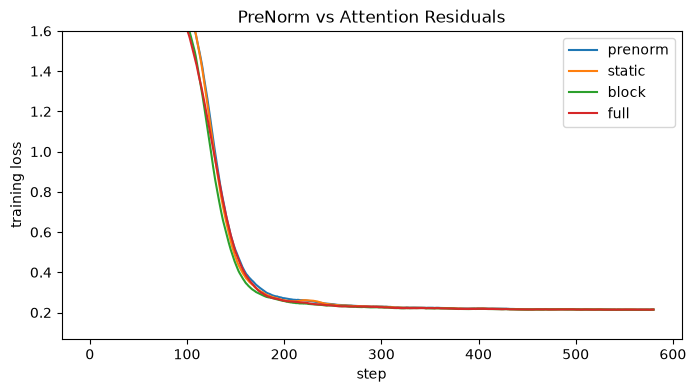

In [4]:
def get_batch(src, B=32):
    ix = torch.randint(0, len(src) - 129, (B,), device=device)
    return src[ix[:, None] + torch.arange(128, device=src.device)], src[ix[:, None] + torch.arange(1, 129, device=src.device)]

def train(residual, steps=600, lr=3e-3):
    seed_everything(0); m = LM(residual).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1); losses = []
    for s in range(steps):
        x, y = get_batch(train_data); loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step(); losses.append(loss.item())
    m.eval(); g = torch.Generator(device="cpu").manual_seed(1); vals = []
    with torch.no_grad():
        for _ in range(20):
            ix = torch.randint(0, len(val_data) - 129, (32,), generator=g).to(device)
            x = val_data[ix[:, None] + torch.arange(128, device=val_data.device)]; y = val_data[ix[:, None] + torch.arange(1, 129, device=val_data.device)]
            vals.append(F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)).item())
    return m, losses, float(np.mean(vals))

runs = {}
for r in ["prenorm", "static", "block", "full"]:
    t0 = time.time(); runs[r] = train(r)
    print(f"{r:8s} val loss {runs[r][2]:.4f}  ({time.time() - t0:.0f}s)")
plt.figure(figsize=(8, 4))
for r, (_, l, _) in runs.items(): plt.plot(np.convolve(l, np.ones(20) / 20, "valid"), label=r)
plt.ylim(None, 1.6); plt.xlabel("step"); plt.ylabel("training loss"); plt.legend(); plt.title("PreNorm vs Attention Residuals"); plt.show()

## PreNorm dilution, measured
For each sub-layer: the norm of its **input** state and of its **output**. With PreNorm the input is the running sum, so it grows with depth and each layer must shout louder to change it. With AttnRes the input is a convex combination of (normalized-key-weighted) earlier outputs, so it stays bounded.

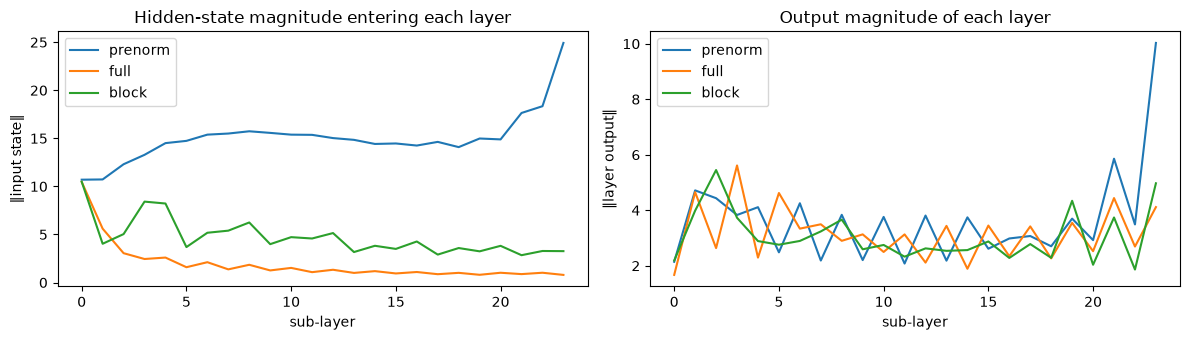

prenorm  input-state norm: first sub-layer 10.7, last 24.9  (growth ×2.3)
full     input-state norm: first sub-layer 10.5, last 0.8  (growth ×0.1)
block    input-state norm: first sub-layer 10.5, last 3.3  (growth ×0.3)


In [5]:
x, _ = get_batch(val_data, 8)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for r in ["prenorm", "full", "block"]:
    m = runs[r][0]
    with torch.no_grad(): m(x)
    o, h = zip(*m.out_norms)
    axes[0].plot(h, label=r); axes[1].plot(o, label=r)
axes[0].set(xlabel="sub-layer", ylabel="‖input state‖", title="Hidden-state magnitude entering each layer"); axes[0].legend()
axes[1].set(xlabel="sub-layer", ylabel="‖layer output‖", title="Output magnitude of each layer"); axes[1].legend(); plt.tight_layout(); plt.show()
for r in ["prenorm", "full", "block"]:
    m = runs[r][0]
    with torch.no_grad(): m(x)
    h = [b for _, b in m.out_norms]
    print(f"{r:8s} input-state norm: first sub-layer {h[0]:.1f}, last {h[-1]:.1f}  (growth ×{h[-1] / h[0]:.1f})")

## What does each layer attend to?
Rows: the layer reading; columns: the source (0 = embedding, $i$ = output of sub-layer $i$). The paper reports three patterns: a strong diagonal (mostly the previous layer, like a residual), persistent attention to the **embedding**, and specialised long-range skips. Weights start uniform (zero query), so every pattern below was learned.

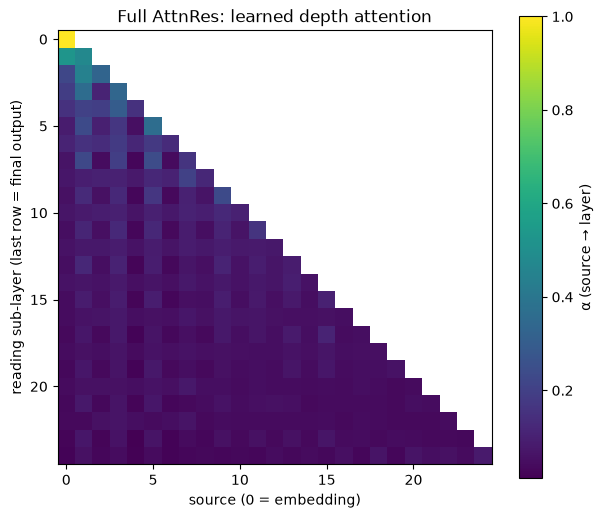

average weight on the embedding: 0.09 | on the immediately preceding layer: 0.14 | uniform would be ~0.12


In [6]:
m = runs["full"][0]
with torch.no_grad(): m(x)
L = len(m.layers); Wd = np.full((L + 1, L + 1), np.nan)
for l in range(L + 1):
    w = m.dattn[l].last.cpu().numpy(); Wd[l, : len(w)] = w
plt.figure(figsize=(7, 6)); plt.imshow(Wd, cmap="viridis"); plt.colorbar(label="α (source → layer)")
plt.xlabel("source (0 = embedding)"); plt.ylabel("reading sub-layer (last row = final output)"); plt.title("Full AttnRes: learned depth attention"); plt.show()
emb_w = np.nanmean(Wd[1:, 0]); prev_w = np.nanmean([Wd[l, l] for l in range(1, L + 1)])
print(f"average weight on the embedding: {emb_w:.2f} | on the immediately preceding layer: {prev_w:.2f} | uniform would be ~{np.nanmean([1 / (l + 1) for l in range(1, L + 1)]):.2f}")

## Takeaways
- AttnRes swaps the fixed $\sum$ of residual streams for a learned softmax over depth: **one vector per layer**, almost free in parameters and compute (depth is ~100, not 1M).
- It removes PreNorm dilution: the input to each layer stays bounded, so outputs no longer need to grow with depth.
- Input dependence matters in the paper: DenseFormer-style static weights gave no gain (1.767 vs 1.766), while Full AttnRes reached 1.737. Softmax beat sigmoid, and one query per layer beat multi-head depth attention.
- Here, all four runs end within about 0.002 of each other (block 0.2133, full 0.2139, static 0.2146, PreNorm 0.2155). This small corpus is learned almost to its floor, so the loss can't separate the variants; the paper's gains were measured at 48B parameters and 1.4T tokens. What the toy does show clearly is the mechanism: PreNorm's input state grows with depth (×2.3 over 24 sub-layers), while AttnRes keeps it bounded, and the depth maps above were learned from a uniform start.
- 2026 picture: three competing replacements for the plain residual: **mHC** (DeepSeek-V4, notebook 76), **AttnRes** (Kimi), and **Gated Residual** (Qwen3.8, notebook 85). Qwen's report found Full AttnRes and Gated Residual reach the same loss at 28 layers.